In [1]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram, plot_bloch_multivector
import matplotlib.pyplot as plt
import numpy as np
simulator = AerSimulator()

In [9]:
# Perfect Bell pair + H to qubit 1 before CNOT
bell = QuantumCircuit(2,2)
bell.h(1)
bell.h(0)
bell.cx(0,1)
bell.measure([0,1], [0,1])

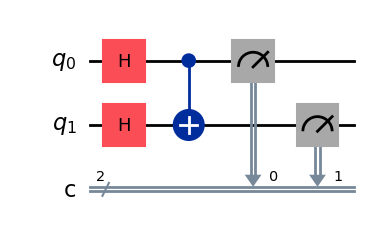

In [10]:
bell.draw(output = 'mpl')

By looking at the qubit circuit we can expect the states to be in an equal superposition of all 4 possible states after the two hadamards. Because of this the CNOT will flip the |10> -> |11> and |11> -> |10>. Because they should have an equal distributprobability, all states should be approxomatly equal when accounting for error. 

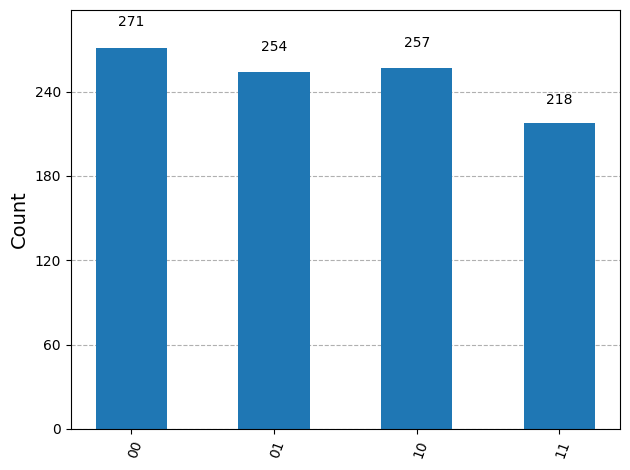

In [11]:
result_bell = simulator.run(transpile(bell, simulator), shots = 1000).result()
plot_histogram(result_bell.get_counts()) # Only 00, 11 (~50% each)